# Vitaliza - Análise Exploratória de Dados (EDA) e Portfólio de Hipóteses MECE (Etapa 2)
**Módulo 2 MBA Inteli | Liderança de Ciência de Dados**  
**Data de Corte Oficial:** 30/09/2026 às 23:59:59 (Horário de Brasília)  
**Última Execução (Base Limpa e Sem Vazamento Pós-Saída):** 01/11/2026  
**Objetivo de Negócio:** Investigar a escalada do churn mensal (5,6% -> 6,6% geral; pico de 8,1% em abr/2026) e estruturar hipóteses causais testáveis para o pipeline de retenção preditiva.

---

### Diretrizes de Governança e Regras de Qualidade Aplicadas (Etapa 1 -> Etapa 2):
1. **Dados Brutos Imutáveis:** A pasta `dados/brutos/` é estritamente somente leitura.
2. **População Oficial Sem Contas Internas:** Expurgadas as `60` contas `@vitaliza.com.br` (`cortesia`), consolidando `32.583` assinaturas pagas históricas (`14.753` pagantes ativos e `17.830` encerradas no corte de `30/09/2026`).
3. **As 5 Dimensões da Qualidade Aplicadas (`ADR 009`):**
   - *Completude:* Flags de preenchimento do onboarding preservadas (`flag_onb_*_preenchido`) e idades inválidas (`<= 1900` ou `>= 2026`, `606` casos) convertidas em `NaN`.
   - *Validade:* Expurgados `3.649` treinos com duração zero e anuladas `951` distâncias GPS `> 200 km` em `atividades_limpas.parquet`.
   - *Consistência:* Mapeados os `11` rótulos de treino para `7` modalidades canônicas (`376.930` registros em inglês integrados).
   - *Unicidade e Fuso:* Convertido o fuso `UTC` do Garmin para `UTC-3` e removidos os `9.383` pares de treinos duplicados (`5.199` Garmin + `4.184` Apple Health), além das cobranças aprovadas em duplicidade no mesmo ciclo/dia.
   - *Temporalidade e Blindagem Contra Vazamento Pós-Cancelamento:* Todas as métricas mensais (`media_atividades_mes`, `media_minutos_mes`, `media_dias_ativos_mes`, `media_sessoes_mes`) são calculadas **estritamente dentro da janela de vigência de cada assinatura (`inicio` até a data de cancelamento — ou até `30/09/2026` para quem segue ativo)** dividida pelos meses de vigência, e a desaceleração recente é medida nas janelas relativas **`D-30` (`atividades_ultimos_30d`)** e **`D-60` (`atividades_31_a_60d`)** anteriores ao cancelamento (eliminando o vazamento pós-cancelamento de olhar para meses fixos do calendário como agosto/setembro de 2026 para quem já havia cancelado antes!).


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Configuração visual
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("Ambiente configurado com sucesso!")


Ambiente configurado com sucesso!


## 1. Carga da Feature Store Consolidada e Higienizada (Corte 30/09/2026)
Carregamos a base processada em `dados/processados/features_eda_corte_set2026.parquet`, gerada após a execução do pipeline das 5 Dimensões da Qualidade e blindagem pós-desfecho (`src/limpeza_qualidade_dados.py` e `src/processar_eda.py`).

In [2]:
df = pd.read_parquet('../dados/processados/features_eda_corte_set2026.parquet')
print(f"Total de assinaturas pagas analisadas: {len(df):,}")
print(f"Status atual da base: {df['status_atual'].value_counts().to_dict()}")
print(f"Pagantes ativos em 30/09/2026: {(df['churn'] == 0).sum():,} (sendo {((df['churn'] == 0) & (df['renovacao_automatica'] == 'sim')).sum():,} com renovação automática ligada)")
print(f"Taxa de churn acumulada histórica no corte: {df['churn'].mean():.2%}")
df.head(3)


Total de assinaturas pagas analisadas: 32,583
Status atual da base: {'expirada': 17758, 'ativa': 14753, 'reembolsada': 72}
Pagantes ativos em 30/09/2026: 14,753 (sendo 12,503 com renovação automática ligada)
Taxa de churn acumulada histórica no corte: 54.72%


,assinatura_id,user_id,plano_atual,canal_cobranca,inicio,status_atual,renovacao_automatica,data_fim,motivo_fim,inicio_dt,data_fim_dt,churn,data_desfecho,data_desfecho,mes_inicio,mes_desfecho,lifetime_dias,lifetime_meses,meses_vigencia,faixa_lifetime,grupo_canal,email,data_cadastro,data_nascimento,sexo,cidade,uf,cep_prefixo,canal_aquisicao,sistema,versao_app,relogio_conectado,data_cadastro_dt,data_nascimento_dt,idade,tem_relogio,cep_prefixo_str,nivel,dias_semana_pretendidos,como_conheceu,flag_onb_objetivo_preenchido,flag_onb_nivel_preenchido,flag_onb_dias_preenchido,total_renovacoes,desligou_renovacao,religou_renovacao,teve_carencia,cancelou_web,teve_chargeback,total_pago_bruto,total_pago_liq,qtd_pagamentos,pagamentos_recusados,meses_registrados,meses_com_uso,total_atividades_mensal,total_ar_livre_mensal,total_video_mensal,total_minutos_mensal,total_dias_ativos,total_sessoes_app,media_minutos_mes_ativo,media_atividades_mes_ativo,total_treinos_log,atividades_ultimos_30d,atividades_31_a_60d,minutos_ultimos_30d,n_modalidades_distintas,duracao_mediana,duracao_iqr,distancia_mediana,distancia_iqr,treinos_em_dupla,prop_treinos_dupla,prop_gps_ok,num_seguidores,num_seguindo,total_posts,total_curtidas,total_tickets,tickets_cobranca,tickets_tecnicos,abriu_push,abriu_email,clicou,motivo_pesquisa_saida,media_atividades_mes,media_minutos_mes,media_dias_ativos_mes,media_sessoes_mes,prop_meses_ativos_vigencia,razao_uso_ultimo_mes
0,s_000000,u_f4d898b7,anual,app_store,2023-10-25,ativa,nao,NaN,NaN,2023-10-25,NaT,0,2026-09-30 23:59:59,2026-09-30 23:59:59,2023-10,2026-09,1072.0000,35,36.0000,6+ meses,Lojas (Apple/Google),joaolima20@hotmail.com,2023-10-18 12:00:00,1981-08-28,M,Rio de Janeiro,RJ,213.0000,meta_ads,ios,5.3.0,apple_watch,2023-10-18 12:00:00,1981-08-28,45.0924,1,213,iniciante,3.0000,ok,1,1,1,2,True,False,False,False,False,599.8000,509.8300,2.0000,0.0000,21.0000,19.0000,39.0000,0.0000,39.0000,1155.0000,39.0000,105.0000,60.7895,2.0526,41.0000,0.0000,0.0000,0.0000,5.0000,40.9000,23.0000,6.9000,2.0400,0.0000,0.0000,1.0000,2.0000,3.0000,9.0000,66.0000,0.0000,0.0000,0.0000,True,False,False,NaN,1.0833,32.0833,1.0833,2.9167,0.5278,0.0000
1,s_000001,u_066eb85c,mensal,web_cartao,2021-11-01,expirada,nao,2025-08-12,renovacao_desligada,2021-11-01,2025-08-12,1,2025-08-12 00:00:00,2025-08-12 00:00:00,2021-11,2025-08,1380.0000,46,46.0000,6+ meses,Web (Cartao/Pix),yasmin.freitas70@icloud.com,2021-10-25 12:00:00,1959-12-16,F,Curitiba,PR,822.0000,meta_ads,ios,5.4.0,nenhum,2021-10-25 12:00:00,1959-12-16,66.7926,0,822,iniciante,3.0000,sla,1,1,1,13,True,False,False,False,False,453.7000,437.8205,13.0000,0.0000,7.0000,7.0000,55.0000,6.0000,49.0000,2227.0000,47.0000,135.0000,318.1429,7.8571,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,1.0000,1.0000,2.0000,18.0000,1.0000,0.0000,0.0000,None,None,None,NaN,1.1957,48.4130,1.0217,2.9348,0.1522,0.0000
2,s_000002,u_fec25b29,mensal,google_play,2020-10-29,expirada,nao,2024-09-08,renovacao_desligada,2020-10-29,2024-09-08,1,2024-09-08 00:00:00,2024-09-08 00:00:00,2020-10,2024-09,1410.0000,47,47.0000,6+ meses,Lojas (Apple/Google),gabriela.campos85@bol.com.br,2020-10-22 12:00:00,1998-07-18,F,SAO PAULO,SP,55.0000,organico,android,5.3.2,garmin,2020-10-22 12:00:00,1998-07-18,28.2053,1,055,avancado,3.0000,procurei app de corrida n aloja,1,1,1,2,True,False,False,False,False,69.8000,59.3300,2.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,3.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,None,None,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 2. Perfilamento Estatístico Robusto: Média, DP, Mediana e IQR (Durante a Vigência)
Comparamos Ativos vs. Cancelados reportando **Média e Desvio Padrão ($s$)** junto com **Mediana e Intervalo Interquartil (IQR)**, calculados estritamente durante os meses de vigência de cada assinatura e nas janelas relativas de 30 e 60 dias antes do cancelamento (`D-30` e `D-60`), evitando qualquer viés de inatividade pós-cancelamento.

In [3]:
metricas_robustas = [
    'atividades_ultimos_30d', 'atividades_31_a_60d',
    'media_atividades_mes', 'media_atividades_mes_ativo',
    'media_minutos_mes', 'media_minutos_mes_ativo',
    'media_dias_ativos_mes', 'media_sessoes_mes',
    'prop_meses_ativos_vigencia', 'n_modalidades_distintas',
    'total_pago_bruto', 'num_seguidores', 'total_posts', 'total_curtidas',
    'duracao_mediana', 'distancia_mediana', 'idade'
]

perfil_rows = []
for m in metricas_robustas:
    s_atv = df[df['churn'] == 0][m].dropna()
    s_cnc = df[df['churn'] == 1][m].dropna()
    med_atv = s_atv.median()
    med_cnc = s_cnc.median()
    var_mediana_pct = ((med_cnc - med_atv) / med_atv * 100.0) if med_atv != 0 else np.nan
    perfil_rows.append({
        'Métrica': m,
        'Ativo_Média': s_atv.mean(),
        'Ativo_DP': s_atv.std(),
        'Ativo_Mediana': med_atv,
        'Ativo_IQR': s_atv.quantile(0.75) - s_atv.quantile(0.25),
        'Cancelado_Média': s_cnc.mean(),
        'Cancelado_DP': s_cnc.std(),
        'Cancelado_Mediana': med_cnc,
        'Cancelado_IQR': s_cnc.quantile(0.75) - s_cnc.quantile(0.25),
        'Variação_Mediana_%': var_mediana_pct
    })

df_perfil = pd.DataFrame(perfil_rows)
display(df_perfil)


,Métrica,Ativo_Média,Ativo_DP,Ativo_Mediana,Ativo_IQR,Cancelado_Média,Cancelado_DP,Cancelado_Mediana,Cancelado_IQR,Variação_Mediana_%
0,atividades_ultimos_30d,9.4202,7.5180,8.0000,10.0000,1.7786,3.7899,0.0000,2.0000,-100.0000
1,atividades_31_a_60d,8.4337,7.3298,8.0000,11.0000,2.9869,5.8706,0.0000,4.0000,-100.0000
2,media_atividades_mes,6.4077,5.7201,4.7895,7.3750,4.6587,5.4229,2.5417,6.6667,-46.9322
3,media_atividades_mes_ativo,7.2521,5.7813,6.0000,7.8636,5.2365,5.0668,3.6667,6.5714,-38.8889
4,media_minutos_mes,283.7170,287.8910,194.8333,313.7333,209.4273,274.3632,107.8333,277.8333,-44.6536
5,media_minutos_mes_ativo,321.4306,295.4256,241.2500,335.6000,234.5166,260.2435,154.0500,277.1857,-36.1451
6,media_dias_ativos_mes,5.2899,4.0695,4.3000,5.9000,3.8695,4.0385,2.5000,5.7345,-41.8605
7,media_sessoes_mes,10.7178,8.6034,8.2857,10.9231,10.6070,11.5136,6.8000,14.0000,-17.9310
8,prop_meses_ativos_vigencia,0.8393,0.2538,1.0000,0.2500,0.6381,0.3964,0.8125,0.7500,-18.7500
9,n_modalidades_distintas,4.7081,1.2762,5.0000,2.0000,1.6047,2.1043,0.0000,4.0000,-100.0000


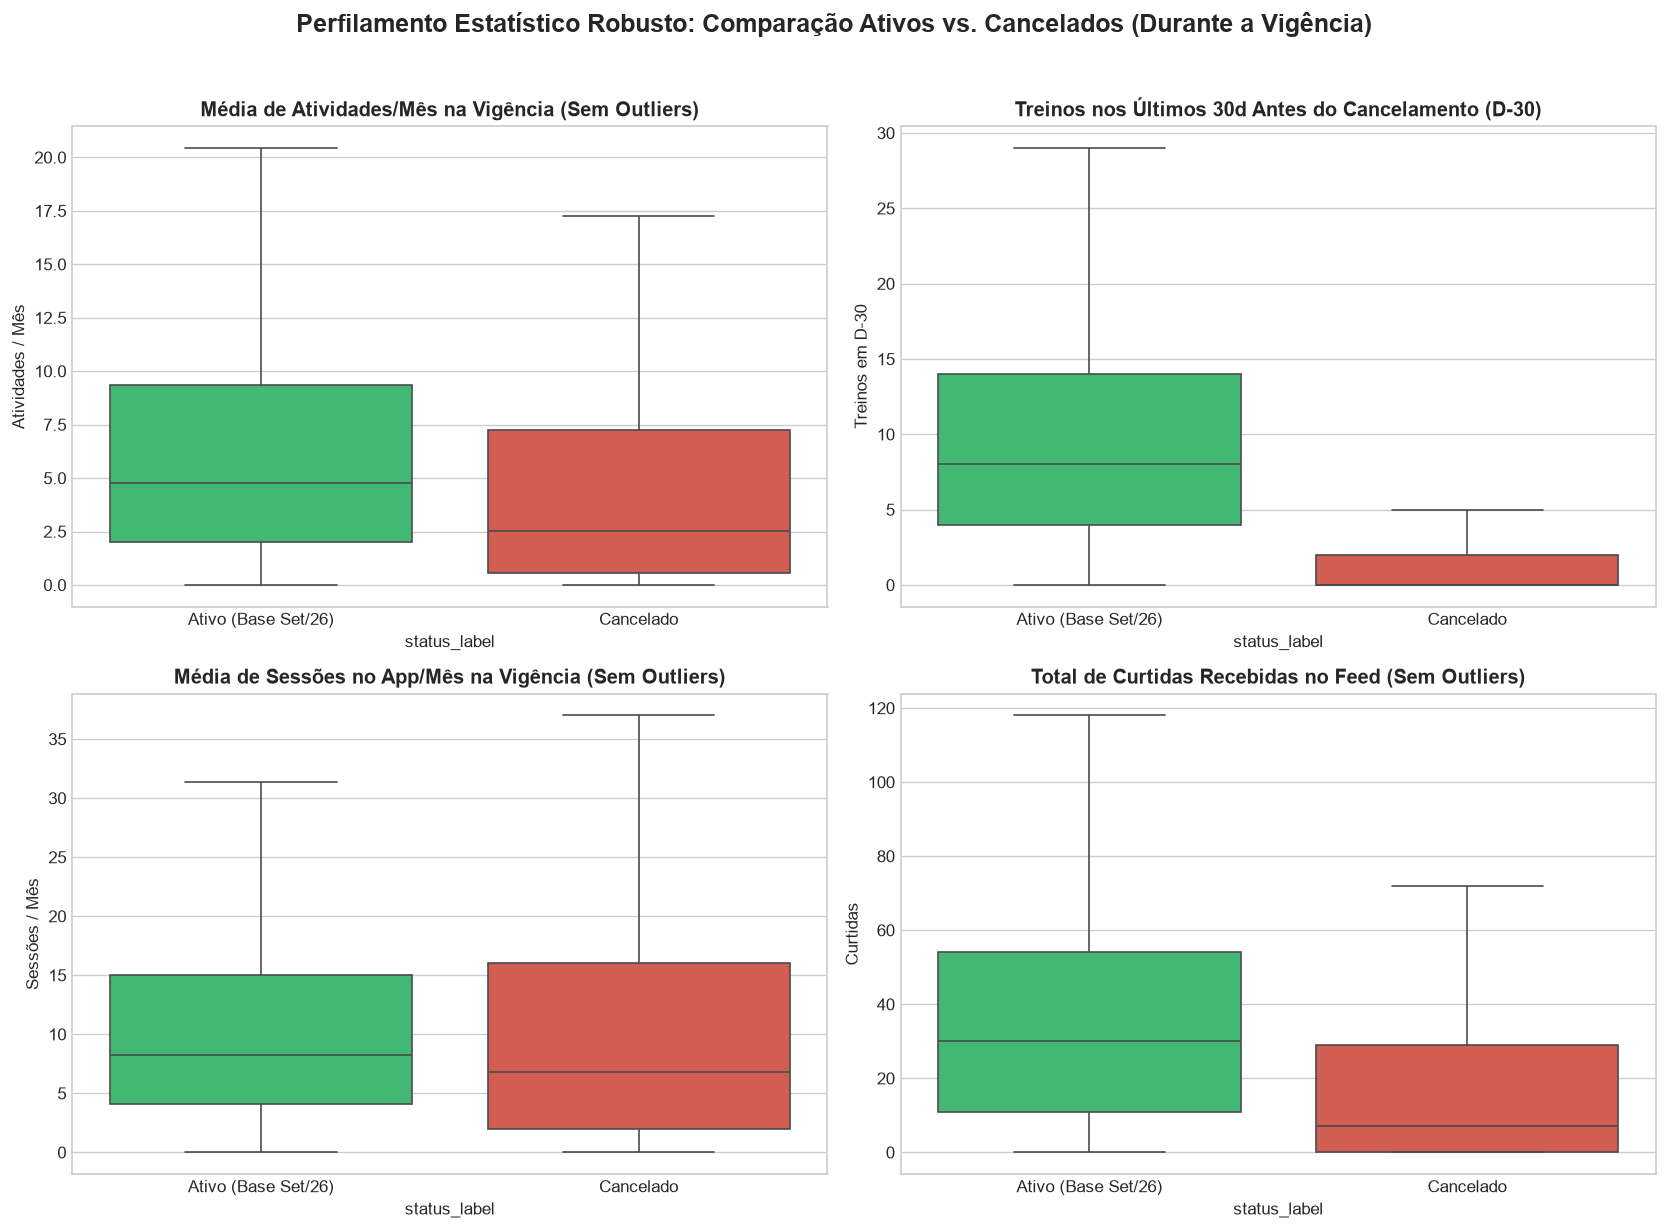

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
df['status_label'] = df['churn'].map({0: 'Ativo (Base Set/26)', 1: 'Cancelado'})
palette = {'Ativo (Base Set/26)': '#2ECC71', 'Cancelado': '#E74C3C'}

sns.boxplot(data=df, x='status_label', y='media_atividades_mes', ax=axes[0, 0], palette=palette, hue='status_label', legend=False, showfliers=False)
axes[0, 0].set_title('Média de Atividades/Mês na Vigência (Sem Outliers)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Atividades / Mês')

sns.boxplot(data=df, x='status_label', y='atividades_ultimos_30d', ax=axes[0, 1], palette=palette, hue='status_label', legend=False, showfliers=False)
axes[0, 1].set_title('Treinos nos Últimos 30d Antes do Cancelamento (D-30)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Treinos em D-30')

sns.boxplot(data=df, x='status_label', y='media_sessoes_mes', ax=axes[1, 0], palette=palette, hue='status_label', legend=False, showfliers=False)
axes[1, 0].set_title('Média de Sessões no App/Mês na Vigência (Sem Outliers)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Sessões / Mês')

sns.boxplot(data=df, x='status_label', y='total_curtidas', ax=axes[1, 1], palette=palette, hue='status_label', legend=False, showfliers=False)
axes[1, 1].set_title('Total de Curtidas Recebidas no Feed (Sem Outliers)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Curtidas')

plt.suptitle('Perfilamento Estatístico Robusto: Comparação Ativos vs. Cancelados (Durante a Vigência)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Análise de Sobrevivência e Cohorts de Lifetime (O "Vale da Morte" M2/M3)
Analisamos a curva de sobrevivência e taxa de churn estratificada por:
1. **Faixas de Tempo de Casa (Lifetime):** 0 meses (<30d), 1 mês (30-59d), 2 meses (60-89d), 3 meses (90-119d), 4-5 meses e 6+ meses.
2. **Tipo de Contrato:** Mensal vs. Anual.
3. **Canal de Cobrança:** Lojas (App Store e Google Play) vs. Meios Próprios Web (Cartão e Pix).

=== Churn por Faixa de Lifetime e Plano ===


,plano_atual,faixa_lifetime,Total,Cancelados,Taxa_Churn
0,anual,0 meses (<30d),532,89,16.7293
1,anual,1 mes (30-59d),366,0,0.0000
2,anual,2 meses (60-89d),338,0,0.0000
3,anual,3 meses (90-119d),297,0,0.0000
4,anual,4-5 meses,724,0,0.0000
5,anual,6+ meses,10770,4460,41.4113
6,mensal,0 meses (<30d),904,199,22.0133
7,mensal,1 mes (30-59d),1876,1214,64.7122
8,mensal,2 meses (60-89d),2047,1567,76.5511
9,mensal,3 meses (90-119d),1748,1386,79.2906


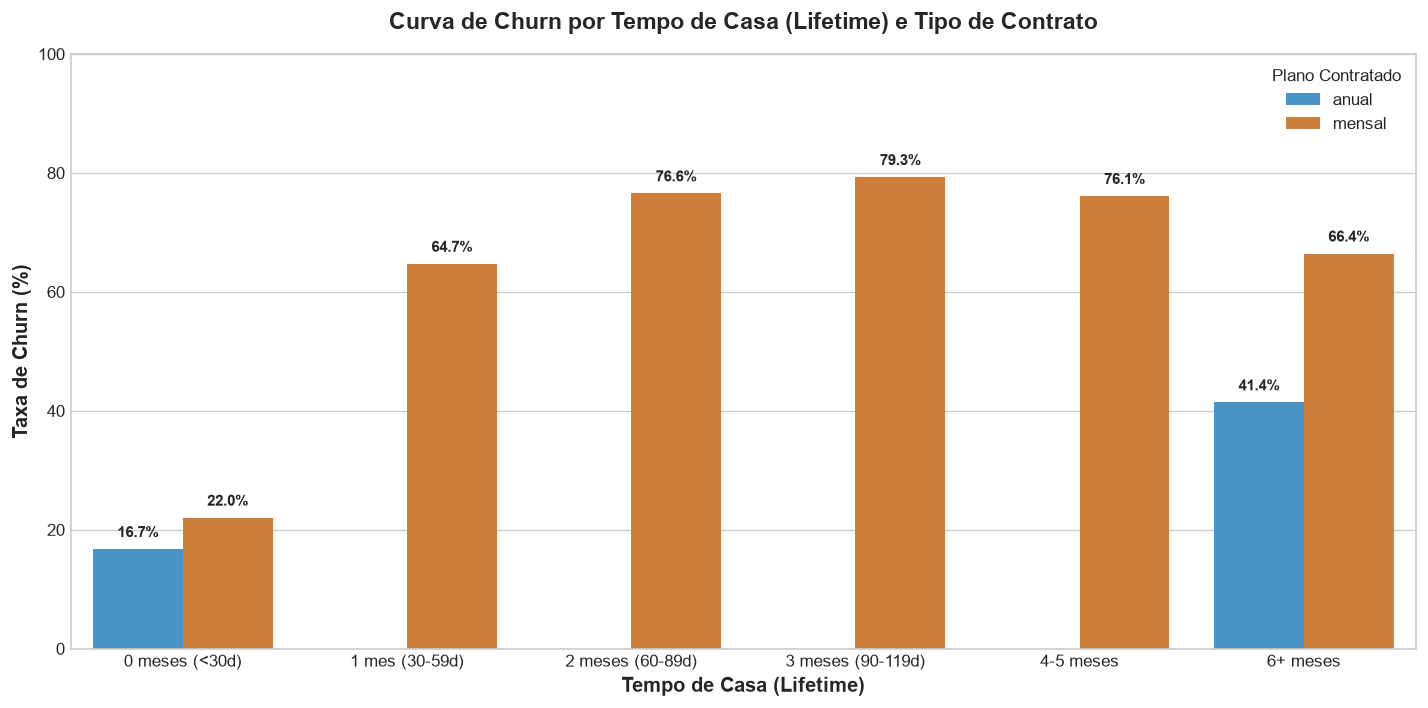

In [5]:
order_life = ['0 meses (<30d)', '1 mes (30-59d)', '2 meses (60-89d)', '3 meses (90-119d)', '4-5 meses', '6+ meses']

print("=== Churn por Faixa de Lifetime e Plano ===")
ct_life_plano = df.groupby(['plano_atual', 'faixa_lifetime'])['churn'].agg(
    Total='count',
    Cancelados='sum',
    Taxa_Churn=lambda s: s.mean() * 100
).reindex(order_life, level=1).reset_index()
display(ct_life_plano)

# Gráfico de barras da curva de churn
plt.figure(figsize=(12, 6))
sns.barplot(data=ct_life_plano, x='faixa_lifetime', y='Taxa_Churn', hue='plano_atual', order=order_life, palette={'anual': '#3498DB', 'mensal': '#E67E22'})
plt.title('Curva de Churn por Tempo de Casa (Lifetime) e Tipo de Contrato', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tempo de Casa (Lifetime)', fontsize=12, fontweight='bold')
plt.ylabel('Taxa de Churn (%)', fontsize=12, fontweight='bold')
plt.ylim(0, 100)
for p in plt.gca().patches:
    h = p.get_height()
    if h > 0:
        plt.gca().annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 1.5),
                           ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.legend(title='Plano Contratado')
plt.tight_layout()
plt.show()


## 4. Diagnóstico do "Ponto Cego" de Cancelamento
Mapeamos a proporção de cancelamentos que ocorreram sem registro na pesquisa de saída do app Vitaliza:
- **Cancelamentos via Stores (Apple App Store e Google Play):** Efetuados externamente nos ajustes do sistema operacional do smartphone sem nunca abrir tela de pesquisa no app Vitaliza (`100%` de ponto cego).
- **Cancelamentos Involuntários:** Falhas definitivas de cobrança (`1.321` casos / `7,41%`) e chargebacks (`292` casos / `1,64%`).
- **Pesquisa de Saída (`pesquisa_saida.csv`):** Iniciada apenas em `01/06/2026` e restrita aos canais Web (`Cartão` e `Pix`), cobrindo apenas `353` dos `17.830` encerramentos históricos (`1,98%`).

In [6]:
cancelados_df = df[df['churn'] == 1]
tot_canc = len(cancelados_df)

com_pesquisa = cancelados_df['motivo_pesquisa_saida'].notna().sum()
sem_pesquisa = tot_canc - com_pesquisa

print(f"Total de Cancelamentos Históricos: {tot_canc:,}")
print(f"Cancelamentos COM Pesquisa de Saída: {com_pesquisa} ({com_pesquisa/tot_canc:.2%})")
print(f"Cancelamentos no PONTO CEGO (Sem Pesquisa): {sem_pesquisa:,} ({sem_pesquisa/tot_canc:.2%})")

ponto_cego_canal = cancelados_df.groupby('canal_cobranca').agg(
    Total_Cancelados=('user_id', 'count'),
    Com_Pesquisa=('motivo_pesquisa_saida', lambda s: s.notna().sum()),
    Prop_Pesquisa_Pct=('motivo_pesquisa_saida', lambda s: s.notna().mean() * 100),
    Falhas_Pagamento=('motivo_fim', lambda s: (s == 'falha_pagamento').sum()),
    Chargebacks=('motivo_fim', lambda s: (s == 'chargeback').sum())
).reset_index()
display(ponto_cego_canal)


Total de Cancelamentos Históricos: 17,830
Cancelamentos COM Pesquisa de Saída: 353 (1.98%)
Cancelamentos no PONTO CEGO (Sem Pesquisa): 17,477 (98.02%)


,canal_cobranca,Total_Cancelados,Com_Pesquisa,Prop_Pesquisa_Pct,Falhas_Pagamento,Chargebacks
0,app_store,5775,0,0.0000,249,95
1,google_play,5984,0,0.0000,272,88
2,web_cartao,4093,225,5.4972,671,69
3,web_pix,1978,128,6.4712,129,40


## 5. Poder Discriminatório Univariado (AUC-ROC) Sem Vazamento Pós-Cancelamento
Avaliamos a capacidade discriminatória univariada de cada preditor em relação ao cancelamento histórico.
- **Blindagem Metodológica:** Excluímos variáveis fixas no calendário de fim de período (`atividades_set26`, `atividades_ago26`) — que geravam falso sinal porque quem cancelou meses antes naturalmente tem zero treinos em setembro — e excluímos o próprio evento de saída (`desligou_renovacao`). Em seu lugar, avaliamos **janelas móveis relativas ao cancelamento (`D-30` e `D-60` antes do cancelamento, ou antes do corte `30/09/2026` para ativos)** e **médias restritas aos meses de vigência ativa da assinatura**.

In [7]:
variaveis_preditoras = [
    ('atividades_ultimos_30d', 'Treinos nos Últimos 30d Antes do Cancelamento (D-30)', 'Uso'),
    ('razao_uso_ultimo_mes', 'Razão de Uso Recente (D-30 vs Média Vigência)', 'Uso'),
    ('atividades_31_a_60d', 'Treinos entre 31d e 60d Antes do Cancelamento (D-60)', 'Uso'),
    ('n_modalidades_distintas', 'Diversidade de Modalidades (7 Canônicas)', 'Uso'),
    ('prop_meses_ativos_vigencia', 'Proporção de Meses Ativos na Vigência', 'Uso'),
    ('media_dias_ativos_mes', 'Média de Dias Ativos/Mês (Na Vigência)', 'Uso'),
    ('media_atividades_mes', 'Média de Atividades/Mês (Na Vigência)', 'Uso'),
    ('media_minutos_mes', 'Média de Minutos de Treino/Mês (Na Vigência)', 'Uso'),
    ('media_sessoes_mes', 'Média de Sessões no App/Mês (Na Vigência)', 'Uso'),
    ('total_ar_livre_mensal', 'Total Atividades Ar Livre (GPS)', 'Uso'),
    ('total_video_mensal', 'Total Atividades Vídeo Guiado', 'Uso'),
    ('prop_gps_ok', 'Proporção Treinos com GPS Válido', 'Uso'),
    ('lifetime_dias', 'Lifetime em Dias', 'Contrato'),
    ('total_pago_bruto', 'Total Pago Bruto (LTV Histórico)', 'Contrato'),
    ('total_renovacoes', 'Total de Renovações Efetuadas', 'Contrato'),
    ('teve_carencia', 'Entrou em Período de Carência', 'Contrato'),
    ('pagamentos_recusados', 'Cobranças Recusadas', 'Contrato'),
    ('total_tickets', 'Total de Tickets de Suporte', 'Contrato'),
    ('treinos_em_dupla', 'Treinos com Parceiro/Grupo', 'Social'),
    ('prop_treinos_dupla', 'Proporção Treinos em Dupla', 'Social'),
    ('num_seguidores', 'Número de Seguidores', 'Social'),
    ('num_seguindo', 'Número de Usuários que Segue', 'Social'),
    ('total_posts', 'Posts Publicados no Feed', 'Social'),
    ('total_curtidas', 'Curtidas Recebidas no Feed', 'Social'),
    ('idade', 'Idade do Usuário (Higienizada)', 'Entrada'),
    ('tem_relogio', 'Possui Smartwatch Conectado', 'Entrada'),
    ('dias_semana_pretendidos', 'Dias/Semana Pretendidos (Onboarding)', 'Entrada'),
]

auc_results = []
y = df['churn'].values

for col, nome, galho in variaveis_preditoras:
    s = df[col].fillna(df[col].median()).values
    auc = roc_auc_score(y, s)
    direcao = 'Aumenta Churn' if auc >= 0.5 else 'Reduz Churn (Protetor)'
    auc_efetivo = max(auc, 1.0 - auc)
    auc_results.append({
        'Galho MECE': galho,
        'Variável': col,
        'Nome Legível': nome,
        'AUC Discriminatório': auc_efetivo,
        'Efeito': direcao
    })

df_auc = pd.DataFrame(auc_results).sort_values('AUC Discriminatório', ascending=False)
display(df_auc)


,Galho MECE,Variável,Nome Legível,AUC Discriminatório,Efeito
3,Uso,n_modalidades_distintas,Diversidade de Modalidades (7 Canônicas),0.8653,Reduz Churn (Protetor)
0,Uso,atividades_ultimos_30d,Treinos nos Últimos 30d Antes do Cancelamento ...,0.8488,Reduz Churn (Protetor)
1,Uso,razao_uso_ultimo_mes,Razão de Uso Recente (D-30 vs Média Vigência),0.8458,Reduz Churn (Protetor)
2,Uso,atividades_31_a_60d,Treinos entre 31d e 60d Antes do Cancelamento ...,0.7636,Reduz Churn (Protetor)
22,Social,total_posts,Posts Publicados no Feed,0.7315,Reduz Churn (Protetor)
13,Contrato,total_pago_bruto,Total Pago Bruto (LTV Histórico),0.7267,Reduz Churn (Protetor)
23,Social,total_curtidas,Curtidas Recebidas no Feed,0.7131,Reduz Churn (Protetor)
10,Uso,total_video_mensal,Total Atividades Vídeo Guiado,0.6515,Reduz Churn (Protetor)
4,Uso,prop_meses_ativos_vigencia,Proporção de Meses Ativos na Vigência,0.6322,Reduz Churn (Protetor)
5,Uso,media_dias_ativos_mes,Média de Dias Ativos/Mês (Na Vigência),0.6287,Reduz Churn (Protetor)


## 6. Portfólio de Hipóteses MECE para Mitigação do Churn

As análises estatísticas subsidiam o portfólio de hipóteses causais testáveis estruturadas nos galhos MECE:

### Galho 1: Características de Entrada e Expectativa (Quem entrou?)
- **H1.1: Gap de Expectativa no Onboarding:** Usuários que declaram meta de alta frequência (>= 4 dias/semana) e praticam < 2 dias no M1 sofrem frustração psicológica e churnam precocemente.
- **H1.2: Oportunismo de Cupom e Sensibilidade ao Preço Cheio:** Assinantes atraídos por cupom de influenciador no 1º ano (R$ 239,90) têm maior propensão a cancelar na renovação para o preço cheio (R$ 299,90).

### Galho 2: Comportamento de Uso e Produto (O que faz no app?)
- **H2.1: Queda Antecipada de Atividade nas Janelas Relativas (D-30 e D-60 antes do Desfecho):** O churn é precedido por uma desaceleração real de treinos nos 30 a 60 dias que antecedem o término da assinatura, bem como por menor regularidade mensal durante a vigência.
- **H2.2: Diversidade Esportiva vs. Monotonia de Modalidade:** Praticantes que exploram múltiplas modalidades canônicas (`n_modalidades_distintas`) apresentam retenção muito superior aos restritos a uma única modalidade ou apenas vídeo guiado.

### Galho 3: Ciclo de Vida, Financeiro e Suporte (Há quanto tempo e qual vínculo?)
- **H3.1: Vale da Morte do Plano Mensal no M2/M3:** O plano mensal apresenta churn de `76,55%` no 2º mês e `79,29%` no 3º mês devido à ausência de barreira contratual de saída.
- **H3.2: Cancelamento Involuntário por Fricção de Cobrança:** `7,41%` dos cancelamentos (`1.321` casos) são falhas de cobrança não recuperadas e `1,64%` (`292` casos) são chargebacks.

### Galho 4: Comunidade e Ancoragem Social (Está conectado a outros?)
- **H4.1: Blindagem por Laços Sociais no Feed:** Usuários ativos no feed social (`total_posts` e `total_curtidas`) apresentam forte efeito protetor contra o churn.
- **H4.2: Treino em Parceria (Efeito Rede Operacional):** A prática de treinos em dupla (`treino_com != ""`) reduz o risco de cancelamento ao criar compromisso interpessoal.
